In [6]:
from google.colab import drive
import os

drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/TIH-804903/tomato"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

print("Training folder:", os.path.exists(TRAIN_DIR))
print("Validation folder:", os.path.exists(VAL_DIR))

Mounted at /content/drive
Training folder: True
Validation folder: True


Load dataset and apply augmentation

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, models
from torchvision.transforms import v2
from torchvision.models import ResNet18_Weights

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [10]:
import os
import shutil
import torch

from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader

# Copy dataset from Drive to Colab local storage
LOCAL_DIR = "/content/tomato"

if not os.path.exists(LOCAL_DIR):
    print("Copying dataset to local storage...")
    shutil.copytree(DATA_DIR, LOCAL_DIR)

TRAIN_DIR = os.path.join(LOCAL_DIR, "train")
VAL_DIR = os.path.join(LOCAL_DIR, "val")

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training augmentation
train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop((224, 224)),
    v2.ColorJitter(0.3, 0.3, 0.3),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

# Validation: no random augmentation
val_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((256, 256)),
    v2.CenterCrop((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

train_data = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_data = datasets.ImageFolder(VAL_DIR, transform=val_transform)

assert train_data.classes == val_data.classes

NUM_CLASSES = len(train_data.classes)
classes = train_data.classes

train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True,
    num_workers=4, pin_memory=True, persistent_workers=True
)

val_loader = DataLoader(
    val_data, batch_size=64, shuffle=False,
    num_workers=4, pin_memory=True, persistent_workers=True
)

print("Classes:", NUM_CLASSES)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Copying dataset to local storage...
Classes: 10
Training images: 10016
Validation images: 1000
Training batches: 157
Validation batches: 16


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [11]:
images, labels = next(iter(train_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Device:", images.device)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Image shape: torch.Size([64, 3, 224, 224])
Label shape: torch.Size([64])
Device: cuda:0


Train the transfer learning model

In [12]:
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_data,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Optimized DataLoaders ready!")

Optimized DataLoaders ready!


In [13]:
import time
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

EPOCHS = 3
best_val_acc = 0

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(EPOCHS):

    model.train()
    running_loss, correct, total = 0, 0, 0
    start = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 25 == 0:
            print(f"Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)}",
                  flush=True)

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS} completed")
    print(f"Train Loss: {train_loss:.4f} | Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Accuracy: {val_acc:.2f}%")
    print(f"Time: {(time.time()-start)/60:.2f} minutes\n")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "/content/best_resnet18_tomato.pth")

print("Best Validation Accuracy:", round(best_val_acc, 2), "%")

Epoch 1 | Batch 25/157
Epoch 1 | Batch 50/157
Epoch 1 | Batch 75/157
Epoch 1 | Batch 100/157
Epoch 1 | Batch 125/157
Epoch 1 | Batch 150/157

Epoch 1/3 completed
Train Loss: 0.9668 | Accuracy: 71.37%
Val Loss: 0.7253 | Accuracy: 80.00%
Time: 0.75 minutes

Epoch 2 | Batch 25/157
Epoch 2 | Batch 50/157
Epoch 2 | Batch 75/157
Epoch 2 | Batch 100/157
Epoch 2 | Batch 125/157
Epoch 2 | Batch 150/157

Epoch 2/3 completed
Train Loss: 0.7625 | Accuracy: 76.84%
Val Loss: 0.6391 | Accuracy: 79.80%
Time: 0.74 minutes

Epoch 3 | Batch 25/157
Epoch 3 | Batch 50/157
Epoch 3 | Batch 75/157
Epoch 3 | Batch 100/157
Epoch 3 | Batch 125/157
Epoch 3 | Batch 150/157

Epoch 3/3 completed
Train Loss: 0.6856 | Accuracy: 78.10%
Val Loss: 0.6348 | Accuracy: 79.30%
Time: 0.75 minutes

Best Validation Accuracy: 80.0 %


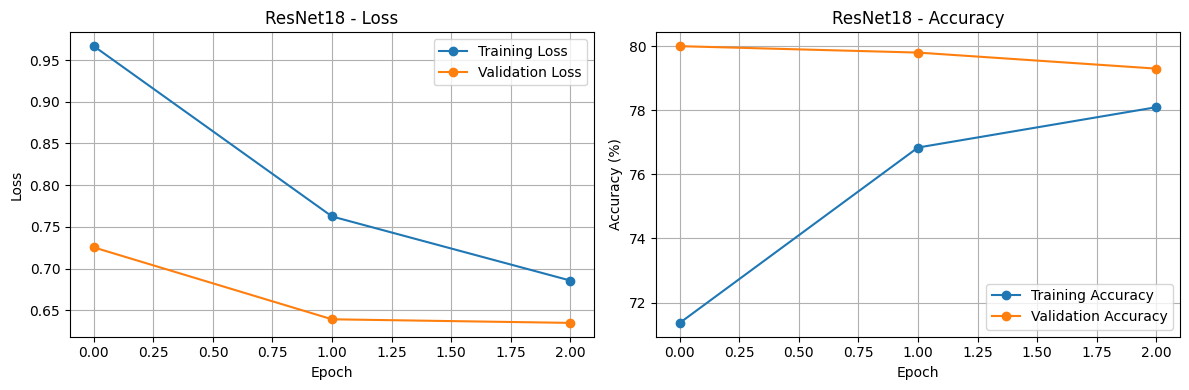

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o', label="Training Loss")
plt.plot(val_losses, marker='o', label="Validation Loss")
plt.title("ResNet18 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, marker='o', label="Training Accuracy")
plt.plot(val_accuracies, marker='o', label="Validation Accuracy")
plt.title("ResNet18 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Validation Accuracy: 80.0 %

Classification Report:

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.96      0.92      0.94       100
                        Tomato___Early_blight       0.86      0.54      0.66       100
                         Tomato___Late_blight       0.87      0.94      0.90       100
                           Tomato___Leaf_Mold       0.83      0.73      0.78       100
                  Tomato___Septoria_leaf_spot       0.74      0.80      0.77       100
Tomato___Spider_mites Two-spotted_spider_mite       0.93      0.64      0.76       100
                         Tomato___Target_Spot       0.66      0.71      0.68       100
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.93      0.93      0.93       100
                 Tomato___Tomato_mosaic_virus       0.67      0.83      0.74       100
                             Tomato___healthy       0.70      0.96      0.81

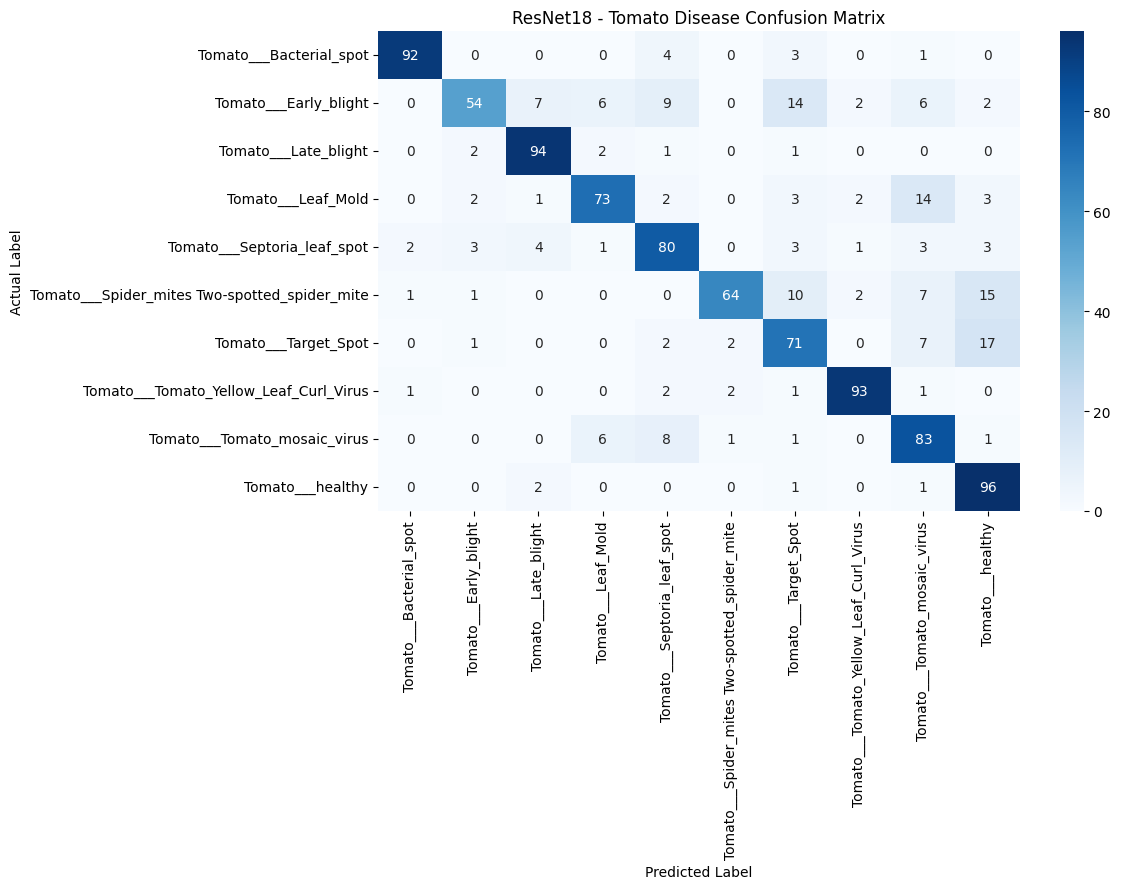

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

model.load_state_dict(
    torch.load("/content/best_resnet18_tomato.pth", map_location=device)
)
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

print("Validation Accuracy:",
      round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.title("ResNet18 - Tomato Disease Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()